In [1]:
import os, json, re, random
import numpy as np
import pandas as pd
from pathlib import Path

from PIL import Image
import matplotlib.pyplot as plt

DATA_ROOT = Path("/home/psivakumar/thesis/data/iu_xray")

PROJ_CSV = DATA_ROOT / "indiana_projections.csv"
REPT_CSV = DATA_ROOT / "indiana_reports.csv"
IMG_DIR  = DATA_ROOT / "images" / "images_normalized"

SPLIT_DIR = DATA_ROOT / "splits"
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("DATA_ROOT:", DATA_ROOT)
print("Projections CSV:", PROJ_CSV, "| exists:", PROJ_CSV.exists())
print("Reports CSV:", REPT_CSV, "| exists:", REPT_CSV.exists())
print("Images dir:", IMG_DIR, "| exists:", IMG_DIR.exists())

assert PROJ_CSV.exists(), "Missing indiana_projections.csv in DATA_ROOT"
assert REPT_CSV.exists(), "Missing indiana_reports.csv in DATA_ROOT"
assert IMG_DIR.exists(), "Missing images/ directory in DATA_ROOT"

proj = pd.read_csv(PROJ_CSV)
rept = pd.read_csv(REPT_CSV)

print("projections shape:", proj.shape)
print("reports shape:", rept.shape)

display(proj.head())
display(rept.head())

print("\nProjections columns:", list(proj.columns))
print("Reports columns:", list(rept.columns))

assert "uid" in proj.columns, "Expected 'uid' in indiana_projections.csv"
assert "uid" in rept.columns, "Expected 'uid' in indiana_reports.csv"

DATA_ROOT: /home/psivakumar/thesis/data/iu_xray
Projections CSV: /home/psivakumar/thesis/data/iu_xray/indiana_projections.csv | exists: True
Reports CSV: /home/psivakumar/thesis/data/iu_xray/indiana_reports.csv | exists: True
Images dir: /home/psivakumar/thesis/data/iu_xray/images/images_normalized | exists: True
projections shape: (7466, 3)
reports shape: (3851, 8)


,uid,filename,projection
0,1,1_IM-0001-4001.dcm.png,Frontal
1,1,1_IM-0001-3001.dcm.png,Lateral
2,2,2_IM-0652-1001.dcm.png,Frontal
3,2,2_IM-0652-2001.dcm.png,Lateral
4,3,3_IM-1384-1001.dcm.png,Frontal


,uid,MeSH,Problems,image,indication,comparison,findings,impression
0,1,normal,normal,Xray Chest PA and Lateral,Positive TB test,None.,The cardiac silhouette and mediastinum size ar...,Normal chest x-XXXX.
1,2,Cardiomegaly/borderline;Pulmonary Artery/enlarged,Cardiomegaly;Pulmonary Artery,"Chest, 2 views, frontal and lateral",Preop bariatric surgery.,None.,Borderline cardiomegaly. Midline sternotomy XX...,No acute pulmonary findings.
2,3,normal,normal,Xray Chest PA and Lateral,"rib pain after a XXXX, XXXX XXXX steps this XX...",NaN,NaN,"No displaced rib fractures, pneumothorax, or p..."
3,4,"Pulmonary Disease, Chronic Obstructive;Bullous...","Pulmonary Disease, Chronic Obstructive;Bullous...","PA and lateral views of the chest XXXX, XXXX a...",XXXX-year-old XXXX with XXXX.,None available,There are diffuse bilateral interstitial and a...,1. Bullous emphysema and interstitial fibrosis...
4,5,Osteophyte/thoracic vertebrae/multiple/small;T...,Osteophyte;Thickening;Lung,Xray Chest PA and Lateral,Chest and nasal congestion.,NaN,The cardiomediastinal silhouette and pulmonary...,No acute cardiopulmonary abnormality.



Projections columns: ['uid', 'filename', 'projection']
Reports columns: ['uid', 'MeSH', 'Problems', 'image', 'indication', 'comparison', 'findings', 'impression']


In [2]:
# 2) Infer key columns (image path & view/projection)
def infer_column(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None

img_col  = infer_column(proj, ["filename", "image", "image_path", "img_path", "path"])
view_col = infer_column(proj, ["projection", "view", "Projection", "View", "projection_type"])

print("Inferred image column:", img_col)
print("Inferred view column:", view_col)

if img_col is None:
    raise ValueError(f"Could not infer image filename/path column. Found columns: {list(proj.columns)}")
if view_col is None:
    raise ValueError(f"Could not infer view/projection column. Found columns: {list(proj.columns)}")

print("\nUnique view labels (top 20):")
display(pd.Series(proj[view_col].astype(str).str.lower().value_counts().head(20)))

Inferred image column: filename
Inferred view column: projection

Unique view labels (top 20):


projection
frontal    3818
lateral    3648
Name: count, dtype: int64

In [3]:
# 3) Normalize view labels and resolve image paths
def normalize_view(v: str) -> str:
    if pd.isna(v):
        return "unknown"
    v = str(v).strip().lower()
    if "frontal" in v or v in {"pa", "ap", "front"}:
        return "frontal"
    if "lateral" in v or v in {"lat", "side"}:
        return "lateral"
    return v  # keep unknown/other as-is

def resolve_image_path(x: str) -> Path:
    x = str(x).strip()
    p = Path(x)
    if p.is_absolute():
        return p
    if x.startswith("images/"):
        return DATA_ROOT / x
    return IMG_DIR / x

proj = proj.copy()
proj["view_norm"] = proj[view_col].apply(normalize_view)
proj["image_path_abs"] = proj[img_col].apply(resolve_image_path)
proj["image_exists"] = proj["image_path_abs"].apply(lambda p: Path(p).exists())

print("Rows with missing image files:", int((~proj["image_exists"]).sum()))
if (~proj["image_exists"]).any():
    display(proj.loc[~proj["image_exists"], ["uid", img_col, "image_path_abs", "view_norm"]].head(25))

print("\nView counts (normalized):")
display(proj["view_norm"].value_counts())

Rows with missing image files: 0

View counts (normalized):


view_norm
frontal    3818
lateral    3648
Name: count, dtype: int64

In [4]:
# 4) UID-level 2-view mapping (1 frontal + 1 lateral)
proj_ok = proj.loc[proj["image_exists"]].copy()

# Deterministic selection when duplicates exist: sort by path string and take first per (uid, view)
proj_ok["image_path_str"] = proj_ok["image_path_abs"].astype(str)
proj_ok = proj_ok.sort_values(["uid", "view_norm", "image_path_str"])

first_per_view = proj_ok.groupby(["uid", "view_norm"], as_index=False).first()

# Pivot to uid -> frontal/lateral columns
pivot = first_per_view.pivot(index="uid", columns="view_norm", values="image_path_str").reset_index()

# Keep only uids that have BOTH views
uid_2view = pivot.dropna(subset=["frontal", "lateral"]).copy()
uid_2view["num_views_present"] = uid_2view[["frontal", "lateral"]].notna().sum(axis=1)

print("Unique UIDs in projections:", proj["uid"].nunique())
print("UIDs with BOTH frontal+lateral (after file existence check):", len(uid_2view))

# Duplicate analysis
dup_counts = proj_ok.groupby(["uid", "view_norm"]).size().reset_index(name="n")
dups = dup_counts[dup_counts["n"] > 1].sort_values("n", ascending=False)

print("UID-view pairs with duplicates (>1 image):", len(dups))
display(dups.head(10))

display(uid_2view.head())

Unique UIDs in projections: 3851
UIDs with BOTH frontal+lateral (after file existence check): 3388
UID-view pairs with duplicates (>1 image): 219


,uid,view_norm,n
2348,1303,frontal,4
3579,1976,frontal,3
3796,2097,lateral,3
5955,3307,frontal,3
4128,2280,frontal,3
7172,3965,frontal,3
7109,3932,frontal,3
147,78,frontal,2
151,80,frontal,2
119,62,frontal,2


view_norm,uid,frontal,lateral,num_views_present
0,1,/home/psivakumar/thesis/data/iu_xray/images/im...,/home/psivakumar/thesis/data/iu_xray/images/im...,2
1,2,/home/psivakumar/thesis/data/iu_xray/images/im...,/home/psivakumar/thesis/data/iu_xray/images/im...,2
2,3,/home/psivakumar/thesis/data/iu_xray/images/im...,/home/psivakumar/thesis/data/iu_xray/images/im...,2
3,4,/home/psivakumar/thesis/data/iu_xray/images/im...,/home/psivakumar/thesis/data/iu_xray/images/im...,2
4,5,/home/psivakumar/thesis/data/iu_xray/images/im...,/home/psivakumar/thesis/data/iu_xray/images/im...,2


In [5]:
# 5) Clean and merge reports (build one 'report' per UID)

find_col = next((c for c in ["findings", "Findings", "FINDINGS"] if c in rept.columns), None)
imp_col  = next((c for c in ["impression", "Impression", "IMPRESSION"] if c in rept.columns), None)

print("Inferred findings column:", find_col)
print("Inferred impression column:", imp_col)

if find_col is None and imp_col is None:
    raise ValueError(f"Could not find findings/impression columns. Found columns: {list(rept.columns)}")

def clean_text(t: str) -> str:
    if pd.isna(t):
        return ""
    t = str(t)
    t = re.sub(r"\s+", " ", t).strip()
    t = re.sub(r"\bX{2,}\b", "", t).strip()
    t = re.sub(r"\s+\.", ".", t)
    return t

rept2 = rept.copy()
rept2["findings_clean"]   = rept2[find_col].apply(clean_text) if find_col else ""
rept2["impression_clean"] = rept2[imp_col].apply(clean_text)  if imp_col else ""

def build_report(row):
    f = row["findings_clean"]
    i = row["impression_clean"]
    if f and i:
        return f"{f}\n\nIMPRESSION: {i}"
    return f or i

rept2["report"] = rept2.apply(build_report, axis=1)
rept2["report_len_words"] = rept2["report"].apply(lambda x: len(str(x).split()) if pd.notna(x) else 0)
rept2["report_len_chars"] = rept2["report"].str.len()

print("Reports with empty text after cleaning:", int((rept2["report_len_words"] == 0).sum()), "/", len(rept2))
display(rept2[["uid", "report_len_words", "report"]].head(5))

Inferred findings column: findings
Inferred impression column: impression
Reports with empty text after cleaning: 25 / 3851


,uid,report_len_words,report
0,1,37,The cardiac silhouette and mediastinum size ar...
1,2,15,Borderline cardiomegaly. Midline sternotomy. E...
2,3,23,"No displaced rib fractures, pneumothorax, or p..."
3,4,111,There are diffuse bilateral interstitial and a...
4,5,47,The cardiomediastinal silhouette and pulmonary...


In [6]:
# 6) Merge: (2-view UIDs) + report, then filter to valid examples
df = uid_2view.merge(rept2[["uid", "report", "report_len_words", "report_len_chars"]], on="uid", how="left")

# Keep only non-empty reports
df = df[df["report_len_words"].fillna(0) > 0].copy()

# Final UID-level dataset for later model notebooks (but we do NOT train here)
df_final = df[["uid", "frontal", "lateral", "report", "report_len_words", "report_len_chars"]].copy()

print("Final df_final shape (UIDs with 2 views + non-empty report):", df_final.shape)
display(df_final.head())

print("\nReport length (words) summary:")
print(df_final["report_len_words"].describe(percentiles=[0.05,0.25,0.5,0.75,0.95]).to_string())

print("\nMissingness (fraction):")
display(df_final.isna().mean().sort_values(ascending=False).to_frame("missing_fraction"))

Final df_final shape (UIDs with 2 views + non-empty report): (3376, 6)


,uid,frontal,lateral,report,report_len_words,report_len_chars
0,1,/home/psivakumar/thesis/data/iu_xray/images/im...,/home/psivakumar/thesis/data/iu_xray/images/im...,The cardiac silhouette and mediastinum size ar...,37,236
1,2,/home/psivakumar/thesis/data/iu_xray/images/im...,/home/psivakumar/thesis/data/iu_xray/images/im...,Borderline cardiomegaly. Midline sternotomy. E...,15,138
2,3,/home/psivakumar/thesis/data/iu_xray/images/im...,/home/psivakumar/thesis/data/iu_xray/images/im...,"No displaced rib fractures, pneumothorax, or p...",23,195
3,4,/home/psivakumar/thesis/data/iu_xray/images/im...,/home/psivakumar/thesis/data/iu_xray/images/im...,There are diffuse bilateral interstitial and a...,111,768
4,5,/home/psivakumar/thesis/data/iu_xray/images/im...,/home/psivakumar/thesis/data/iu_xray/images/im...,The cardiomediastinal silhouette and pulmonary...,47,374



Report length (words) summary:
count    3376.000000
mean       37.320201
std        18.948405
min         3.000000
5%         15.000000
25%        25.000000
50%        34.000000
75%        45.000000
95%        73.000000
max       172.000000

Missingness (fraction):


,missing_fraction
uid,0.0
frontal,0.0
lateral,0.0
report,0.0
report_len_words,0.0
report_len_chars,0.0


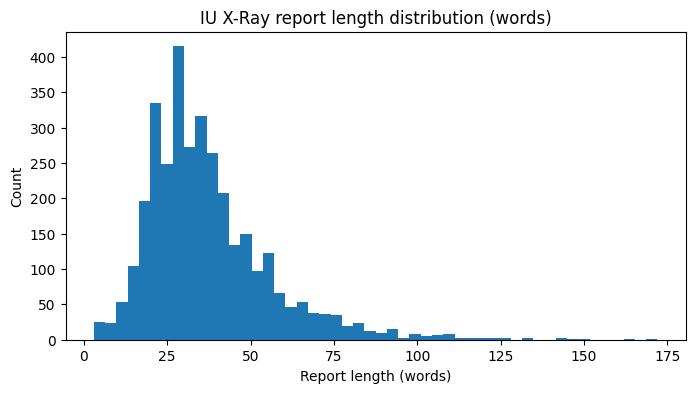

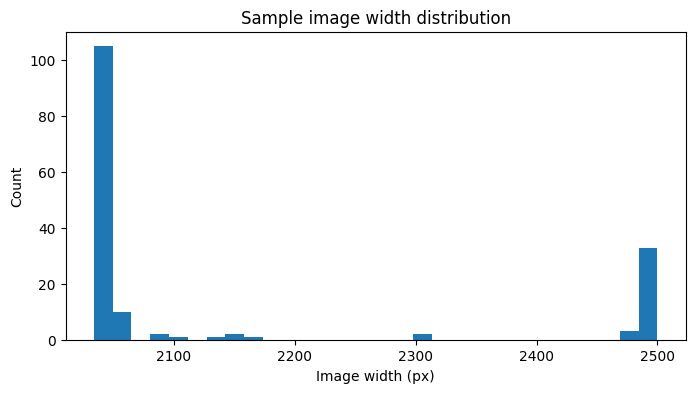

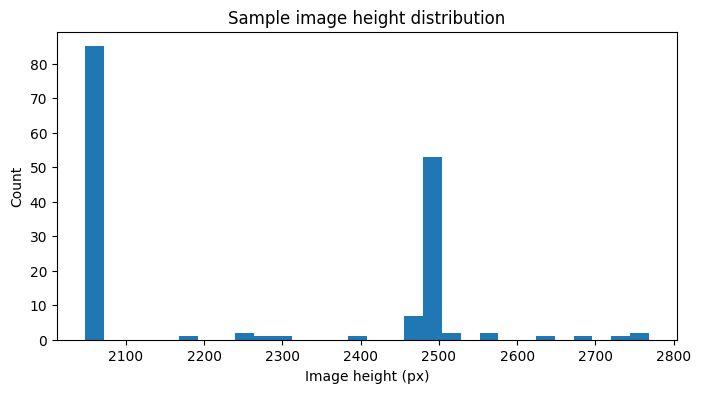

Sample image sizes (first 10): [(2048, 2293), (2143, 2048), (2474, 2048), (2048, 2474), (2500, 2048), (2048, 2725), (2048, 2496), (2048, 2496), (2048, 2251), (2048, 2676)]


In [7]:
# 7)EDA plots
# 7.1 Report length histogram
plt.figure(figsize=(8,4))
plt.hist(df_final["report_len_words"].values, bins=50)
plt.xlabel("Report length (words)")
plt.ylabel("Count")
plt.title("IU X-Ray report length distribution (words)")
plt.show()

# 7.2 Image resolution sampling (frontal + lateral)
sample_n = min(80, len(df_final))
sample_paths = df_final.sample(n=sample_n, random_state=SEED)[["frontal","lateral"]].values.flatten()

sizes = []
for p in sample_paths:
    try:
        with Image.open(p) as im:
            sizes.append(im.size)  # (W,H)
    except Exception:
        pass

if sizes:
    widths  = [s[0] for s in sizes]
    heights = [s[1] for s in sizes]

    plt.figure(figsize=(8,4))
    plt.hist(widths, bins=30)
    plt.xlabel("Image width (px)")
    plt.ylabel("Count")
    plt.title("Sample image width distribution")
    plt.show()

    plt.figure(figsize=(8,4))
    plt.hist(heights, bins=30)
    plt.xlabel("Image height (px)")
    plt.ylabel("Count")
    plt.title("Sample image height distribution")
    plt.show()

print("Sample image sizes (first 10):", sizes[:10])

In [8]:
# 8) Create UID-level train/val/test split ONCE and SAVE it

uids = df_final["uid"].astype(str).unique().tolist()
random.Random(SEED).shuffle(uids)

n_total = len(uids)
n_train = int(0.8 * n_total)
n_val   = int(0.1 * n_total)

train_uids = uids[:n_train]
val_uids   = uids[n_train:n_train+n_val]
test_uids  = uids[n_train+n_val:]

# Save UID lists for reuse in later notebooks
(SPLIT_DIR / "train_uids.txt").write_text("\n".join(train_uids), encoding="utf-8")
(SPLIT_DIR / "val_uids.txt").write_text("\n".join(val_uids), encoding="utf-8")
(SPLIT_DIR / "test_uids.txt").write_text("\n".join(test_uids), encoding="utf-8")

print("Saved splits to:", SPLIT_DIR)
print("Train:", len(train_uids), "Val:", len(val_uids), "Test:", len(test_uids))

# Safety checks: no overlap
assert set(train_uids).isdisjoint(val_uids)
assert set(train_uids).isdisjoint(test_uids)
assert set(val_uids).isdisjoint(test_uids)

✅ Saved splits to: /home/psivakumar/thesis/data/iu_xray/splits
Train: 2700 Val: 337 Test: 339


In [9]:
# 9) Save annotation_full.json + eda_stats.json

records = []
for _, row in df_final.iterrows():
    records.append({
        "uid": str(row["uid"]),
        "frontal": str(row["frontal"]),
        "lateral": str(row["lateral"]),
        "report": row["report"]
    })

ann_path = DATA_ROOT / "annotation_full.json"
with open(ann_path, "w", encoding="utf-8") as f:
    json.dump(records, f, indent=2, ensure_ascii=False)

stats = {
    "data_root": str(DATA_ROOT),
    "total_valid_uids": int(len(df_final)),
    "seed": int(SEED),
    "split_counts": {
        "train": int(len(train_uids)),
        "val": int(len(val_uids)),
        "test": int(len(test_uids)),
    },
    "report_words": {
        "mean": float(df_final["report_len_words"].mean()),
        "std": float(df_final["report_len_words"].std(ddof=1)) if len(df_final) > 1 else 0.0,
        "min": int(df_final["report_len_words"].min()),
        "p25": float(df_final["report_len_words"].quantile(0.25)),
        "median": float(df_final["report_len_words"].quantile(0.50)),
        "p75": float(df_final["report_len_words"].quantile(0.75)),
        "max": int(df_final["report_len_words"].max()),
    }
}

stats_path = DATA_ROOT / "eda_stats.json"
with open(stats_path, "w", encoding="utf-8") as f:
    json.dump(stats, f, indent=2, ensure_ascii=False)

print("Saved:", ann_path)
print("Saved:", stats_path)
print("Example record:")
print(json.dumps(records[0], indent=2, ensure_ascii=False)[:800])

Saved: /home/psivakumar/thesis/data/iu_xray/annotation_full.json
Saved: /home/psivakumar/thesis/data/iu_xray/eda_stats.json
Example record:
{
  "uid": "1",
  "frontal": "/home/psivakumar/thesis/data/iu_xray/images/images_normalized/1_IM-0001-4001.dcm.png",
  "lateral": "/home/psivakumar/thesis/data/iu_xray/images/images_normalized/1_IM-0001-3001.dcm.png",
  "report": "The cardiac silhouette and mediastinum size are within normal limits. There is no pulmonary edema. There is no focal consolidation. There are no  of a pleural effusion. There is no evidence of pneumothorax.\n\nIMPRESSION: Normal chest x-."
}


UID: 3719
Frontal: /home/psivakumar/thesis/data/iu_xray/images/images_normalized/3719_IM-1857-1001.dcm.png
Lateral: /home/psivakumar/thesis/data/iu_xray/images/images_normalized/3719_IM-1857-1002.dcm.png

--- REPORT (first 2000 chars) ---

No active disease.


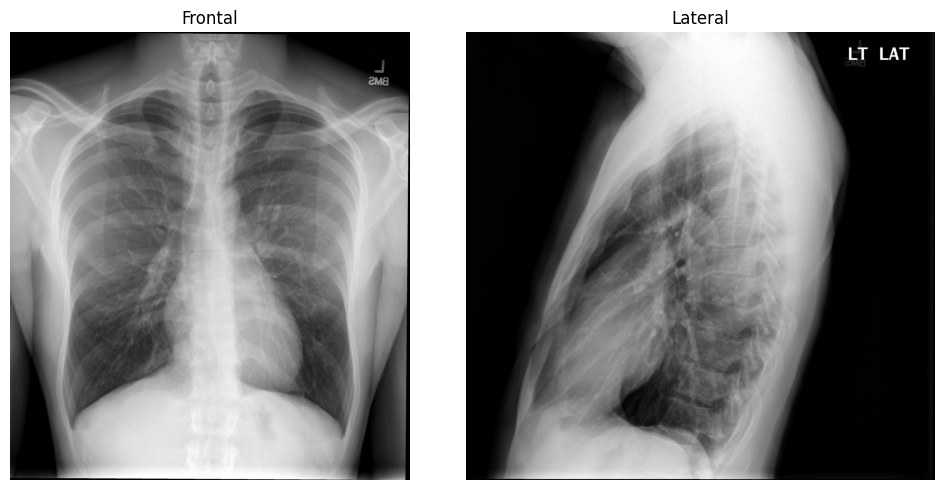

In [10]:
# 10) Print + visualize ONE sample (frontal + lateral + report)

sample = df_final.sample(1, random_state=SEED).iloc[0]

print("UID:", sample["uid"])
print("Frontal:", sample["frontal"])
print("Lateral:", sample["lateral"])
print("\n--- REPORT (first 2000 chars) ---\n")
print(sample["report"][:2000])

# Display images
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, p, title in zip(axes, [sample["frontal"], sample["lateral"]], ["Frontal", "Lateral"]):
    im = Image.open(p).convert("L")
    ax.imshow(im, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()